### 1.Import necessary libraries

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

### Import dataset (Data collection)

In [4]:
cars_data=pd.read_csv(filepath_or_buffer="Cars.csv")

### 3.Data understanding

### 3.1 Perform initial investigation on the data

In [8]:
cars_data.shape

(81, 5)

In [11]:
cars_data.isnull().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [9]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [12]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


### 3.2 Check for the assumptions to perform linear aggression

### Test 1 : Linearity test

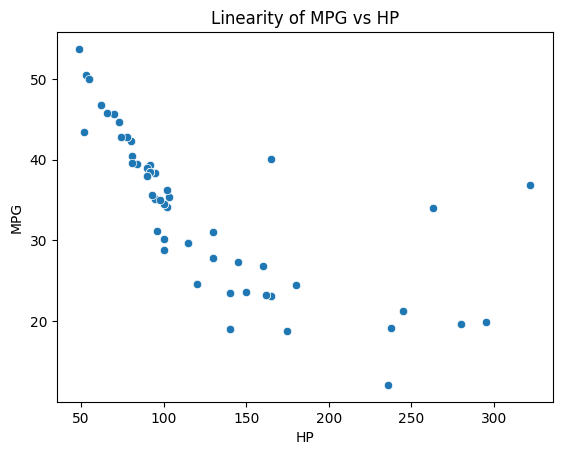

In [17]:
plt.title("Linearity of MPG vs HP")
sns.scatterplot(data=cars_data,x="HP",y="MPG") #this plot is not that much recomended
plt.show()

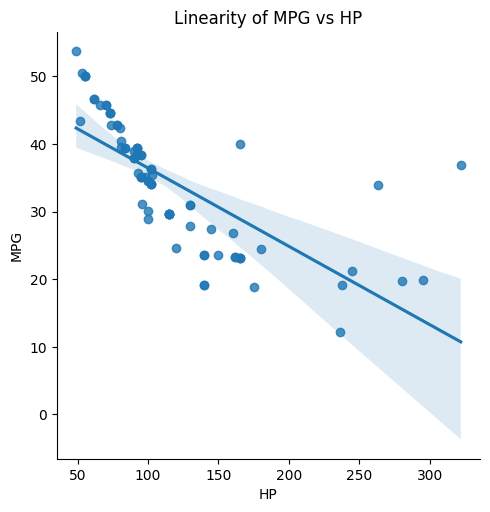

In [21]:
sns.lmplot(data=cars_data,x="HP",y="MPG") #this plot is not that much recomended
plt.title("Linearity of MPG vs HP")
plt.show()


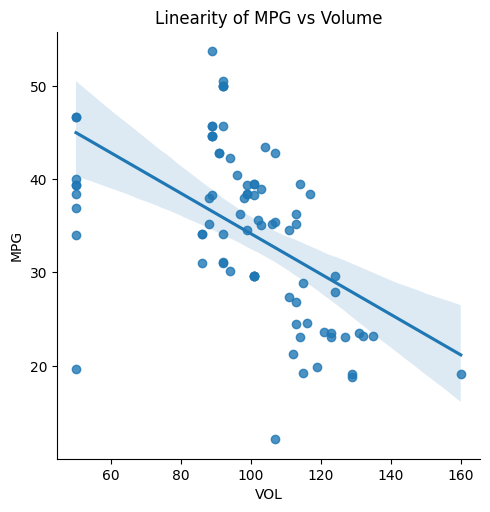

In [23]:
sns.lmplot(data=cars_data,x="VOL",y="MPG") #this plot is not that much recomended
plt.title("Linearity of MPG vs Volume")
plt.show()


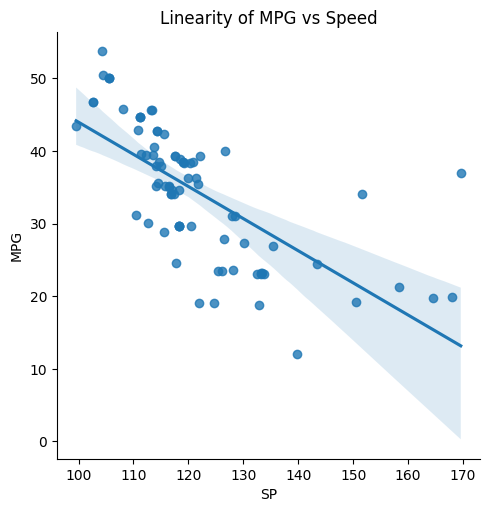

In [24]:
sns.lmplot(data=cars_data,x="SP",y="MPG") #this plot is not that much recomended
plt.title("Linearity of MPG vs Speed")
plt.show()


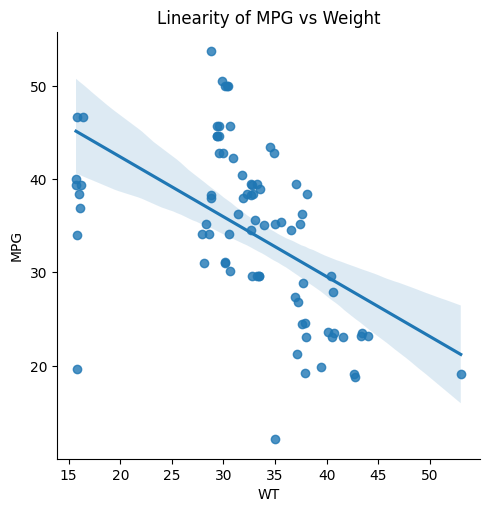

In [25]:
sns.lmplot(data=cars_data,x="WT",y="MPG") #this plot is not that much recomended
plt.title("Linearity of MPG vs Weight")
plt.show()


### Test 1 failed

### Test 2: Normality test

 To check whether the variable follows bell curve, guasian curve, z curve or normal distribution

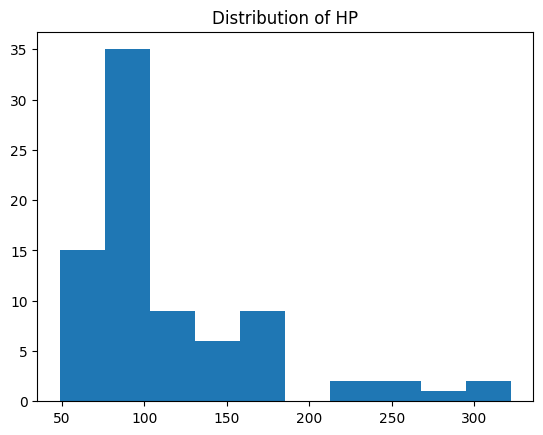

In [27]:
plt.hist(cars_data["HP"])
plt.title("Distribution of HP")
plt.show()

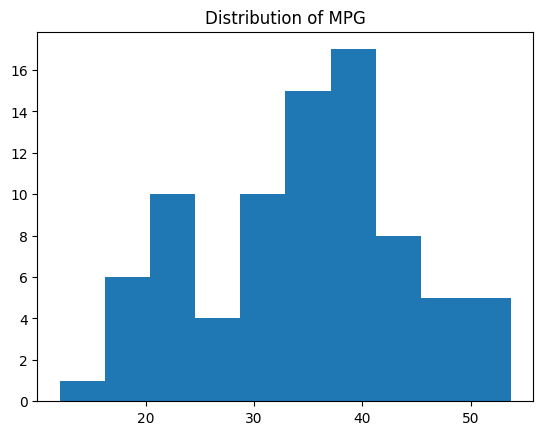

In [28]:
plt.hist(cars_data["MPG"])
plt.title("Distribution of MPG")
plt.show()

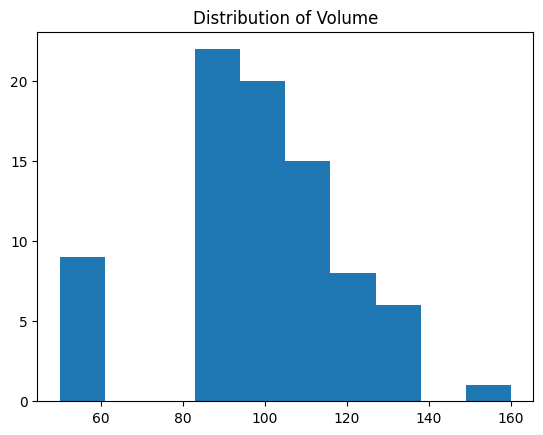

In [29]:
plt.hist(cars_data["VOL"])
plt.title("Distribution of Volume")
plt.show()

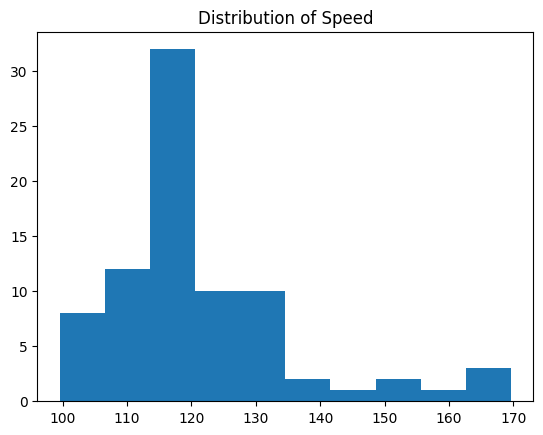

In [30]:
plt.hist(cars_data["SP"])
plt.title("Distribution of Speed")
plt.show()

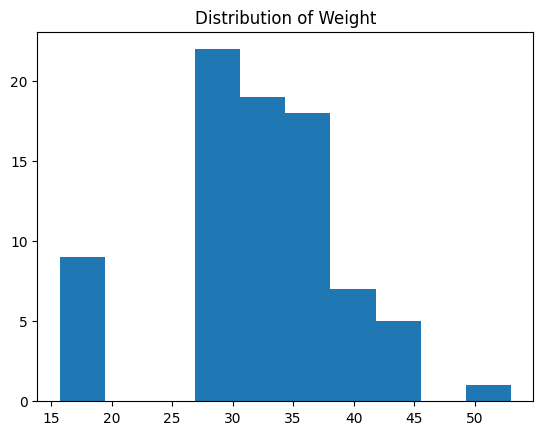

In [31]:
plt.hist(cars_data["WT"])
plt.title("Distribution of Weight")
plt.show()

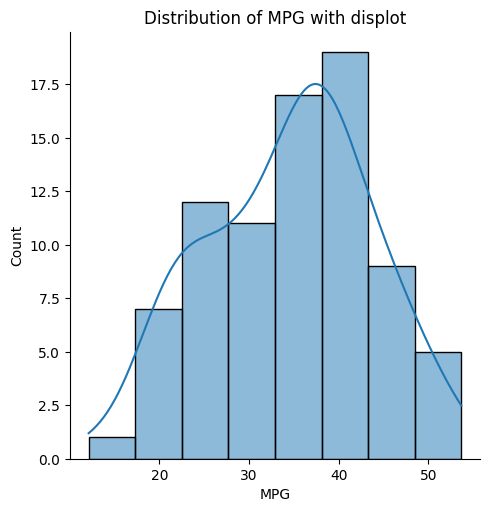

In [36]:
sns.displot(data=cars_data,x="MPG",kde=True)
plt.title("Distribution of MPG with displot")
plt.show()

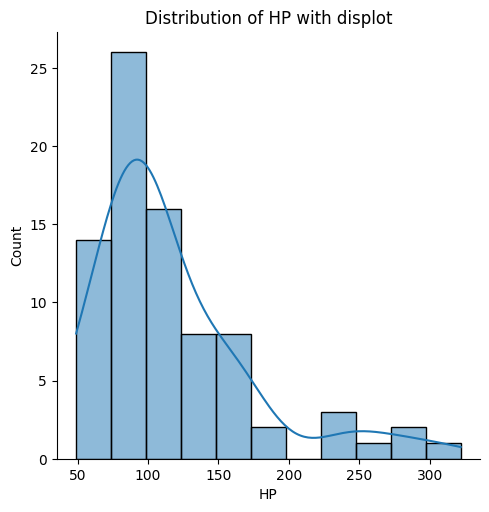

In [37]:
sns.displot(data=cars_data,x="HP",kde=True)
plt.title("Distribution of HP with displot")
plt.show()

### Test 2 normality failed

### Test 3 correlation test (Strength of the relationship between variables)

In [41]:
cars_correlation=cars_data.corr().round(2)  #by default takes pearson correlation coefficient you can change other methods if u want

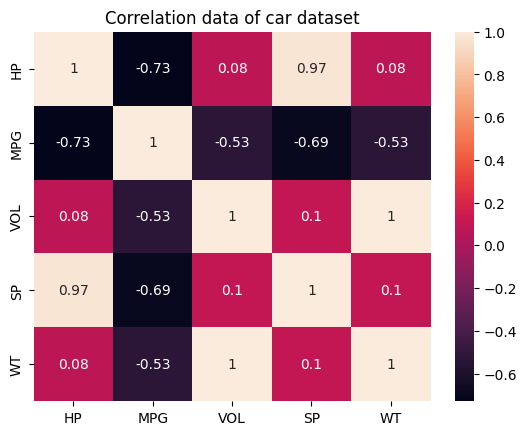

In [43]:
sns.heatmap(data=cars_correlation,annot=True)
plt.title("Correlation data of car dataset")
plt.show()

### Test 3 there is a multicolinearity with the data

### Test 4 auto regression passed as no features in the data is dependent to any time based parameter

### 4. Data preparation

There is nothing to prepare as all features are numeric. Feature enginerring techniques can be applied for data preparation.

**Segeragate input and output**

In [5]:
x=cars_data[["HP","VOL","SP","WT"]]

In [6]:
y=cars_data["MPG"]

### 5. Model building

Import linear regression above

**Calling model**

In [7]:
linear_model=LinearRegression() #algorithm initiated

**Test train split**

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(x,y,test_size=0.20,shuffle=True)

### 6. Model training

In [41]:
linear_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [13]:
linear_model.intercept_ # will be only one value c in y=mx+c

np.float64(34.637004258491174)

In [14]:
linear_model.coef_ # will be 4 value as there are 4 inputs

array([-0.19251662, -0.07581873,  0.35429342, -0.39620636])

### 7.Model testing

### Train data testing

In [42]:
y_predicted_train=linear_model.predict(X_train)

### Test data testing

In [43]:
y_predicted_test=linear_model.predict(X_test)

### Model evaluation

In [46]:
error1=y_train - y_predicted_train
abs(error1).mean()

np.float64(3.495302398458042)

### Evaluation metrics for linear regression

In [55]:
from sklearn.metrics import mean_absolute_error,mean_squared_error, root_mean_squared_error,r2_score


In [28]:
mean_absolute_error(y_train,y_predicted_train) #same units

3.495302398458042

In [49]:
mean_squared_error(y_train,y_predicted_train) #squared output units

20.624539953887748

In [53]:
 root_mean_squared_error(y_train,y_predicted_train) #normalize the units

4.54142488145381

In [56]:
r2_score(y_train,y_predicted_train) 

0.7212863402620457

### The below also creates a linear agression model using stats models previosuly we created using sklearn.linear_model

In [57]:
import statsmodels.formula.api as smf

In [68]:
linear_stats_model=smf.ols(formula="MPG ~ HP+VOL+SP+WT", data=cars_data).fit()

In [74]:
print("R2 square:",linear_stats_model.rsquared.round(3),"\nR2 adjacent square",linear_stats_model.rsquared_adj.round(3))

R2 square: 0.771 
R2 adjacent square 0.758


### R2 square keeps on increasing when additional input features is added but r2 adjacent square doesnt keep increases but decreases, example stated below

#### I add only one feature HP its indirectly propotional to the MPG so we get a value of R2 square +R2 adjacent

In [75]:
linear_stats_model=smf.ols(formula="MPG ~ HP", data=cars_data).fit()
print("R2 square:",linear_stats_model.rsquared.round(3),"\nR2 adjacent square",linear_stats_model.rsquared_adj.round(3))

R2 square: 0.526 
R2 adjacent square 0.52


#### Next i add Speed , speed and hp have relationship so the R2 square or R2 adjacent square is not affected

In [79]:
linear_stats_model=smf.ols(formula="MPG ~ HP+SP", data=cars_data).fit()
print("R2 square:",linear_stats_model.rsquared.round(3),"\nR2 adjacent square",linear_stats_model.rsquared_adj.round(3))

R2 square: 0.533 
R2 adjacent square 0.521


#### I add Hp and volume here volume is not related to hp but it affects the output MPG so you can see there is a steady increase in the R2 square and R2 adjacent square

In [76]:
linear_stats_model=smf.ols(formula="MPG ~ HP+VOL", data=cars_data).fit()
print("R2 square:",linear_stats_model.rsquared.round(3),"\nR2 adjacent square",linear_stats_model.rsquared_adj.round(3))

R2 square: 0.751 
R2 adjacent square 0.744


#### Now i am adding useless features which have relationship with other inputs hence the R2 square and R2 adjacent square doesnt change much. Even the R2 square changes the R2 adjacent square doesnt change if useless features are added

In [77]:
linear_stats_model=smf.ols(formula="MPG ~ HP+VOL+SP", data=cars_data).fit()
print("R2 square:",linear_stats_model.rsquared.round(3),"\nR2 adjacent square",linear_stats_model.rsquared_adj.round(3))

R2 square: 0.77 
R2 adjacent square 0.761


In [78]:
linear_stats_model=smf.ols(formula="MPG ~ HP+VOL+SP+WT", data=cars_data).fit()
print("R2 square:",linear_stats_model.rsquared.round(3),"\nR2 adjacent square",linear_stats_model.rsquared_adj.round(3))

R2 square: 0.771 
R2 adjacent square 0.758


### Test 5 homoscedasticity test after model building and evaluation 

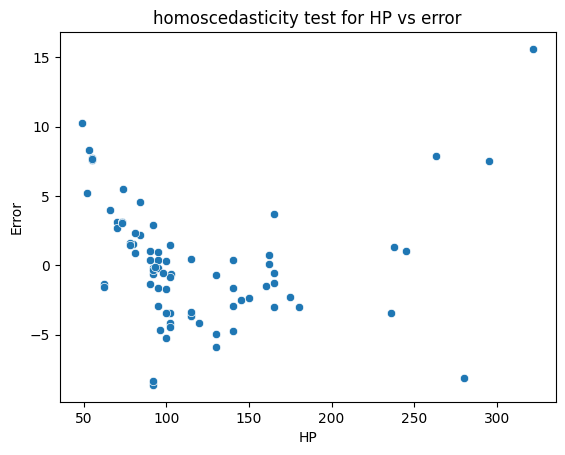

In [29]:
sns.scatterplot(data=cars_data,x="HP",y=error)
plt.ylabel("Error")
plt.title("homoscedasticity test for HP vs error")
plt.show()


A homoscedasticity test checks if the error variance in a regression model is constant across all levels of the independent variables.

The dots should be evenly scattered above and below the center line (\[0\]). If you see dots reaching down to \[-5\] on the left side, you should see them reaching up to \[+5\] on the left side too. 


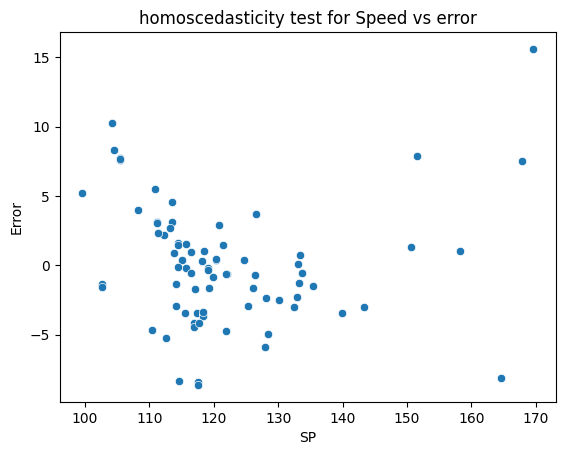

In [30]:
sns.scatterplot(data=cars_data,x="SP",y=error)
plt.ylabel("Error")
plt.title("homoscedasticity test for Speed vs error")
plt.show()


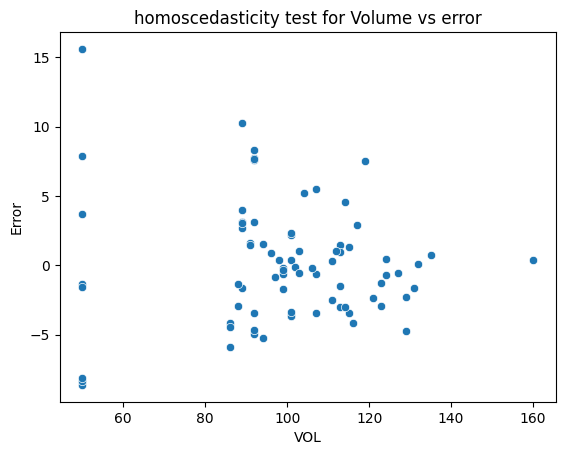

In [31]:
sns.scatterplot(data=cars_data,x="VOL",y=error)
plt.ylabel("Error")
plt.title("homoscedasticity test for Volume vs error")
plt.show()


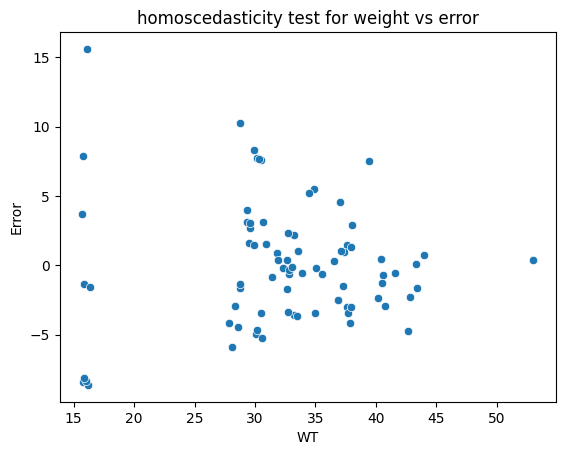

In [32]:
sns.scatterplot(data=cars_data,x="WT",y=error)
plt.ylabel("Error")
plt.title("homoscedasticity test for weight vs error")
plt.show()


### Test 5 homoscedasticity test failed

### Test 6 Zero residual mean test

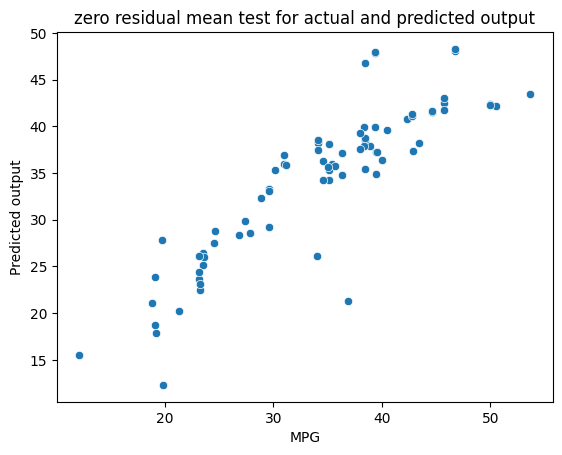

In [36]:
sns.scatterplot(x=y,y=y_predicted)
plt.ylabel("Actual output")
plt.ylabel("Predicted output")
plt.title("zero residual mean test for actual and predicted output")
plt.show()


### Test 6: Zero residual mean test failed

### Train-Test split

In [2]:
from sklearn.metrics

SyntaxError: invalid syntax (938813759.py, line 1)

### 9.Model deployment

In [41]:
from pickle import dump
dump(obj=linear_model,file=open(file="linear_intelligence_file.pkl",mode="wb")) #creating a file with wb (write mode and binary mode)
from pickle import load
linear_intel_pkl=load(file=open(file="linear_intelligence_file.pkl",mode="rb")) #loading a file with wb (read mode and binary mode)
linear_intel_pkl

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [45]:
    linear_intel_pkl.predict(x)

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21